In [1]:
import torch
import torchvision
from torchvision.datasets import CIFAR10

In [ ]:
# MNIST -> 1x28x28 -> 784
# CIFAR -> 3x32x32 -> 1024 * 3 = 3072

In [2]:
from torchvision import transforms as T

# tfs = T.Compose( [T.Resize((28, 28)), T.Grayscale(num_output_channels = 3), T.ToTensor()] ) # MNIST
tfs = T.Compose( [T.Resize((32, 32)), T.ToTensor()] )

ds = CIFAR10(root = "datasets", train = True, download = True, transform = tfs)
ts_ds = CIFAR10(root = "datasets", train = False, download = True, transform = tfs)
classes = ds.classes
print(classes)
n_cls = len(classes) # validation data is not used in this example, but it can be used for hyperparameter tuning and model selection.
n_cls

Files already downloaded and verified
Files already downloaded and verified
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


10

In [3]:
from torch.utils.data import random_split, DataLoader

total_len = len(ds)
tr_len = int(total_len * 0.9) # int
vl_len = total_len - tr_len # int - int = int
tr_len, vl_len

(45000, 5000)

In [4]:
tr_ds, vl_ds = random_split(dataset = ds, lengths=[tr_len, vl_len]) # train va validation datasetlarini ajratamiz
print(len(tr_ds),len(vl_ds))  # train va validation datasetlarining uzunliklarini chiqaramiz

45000 5000


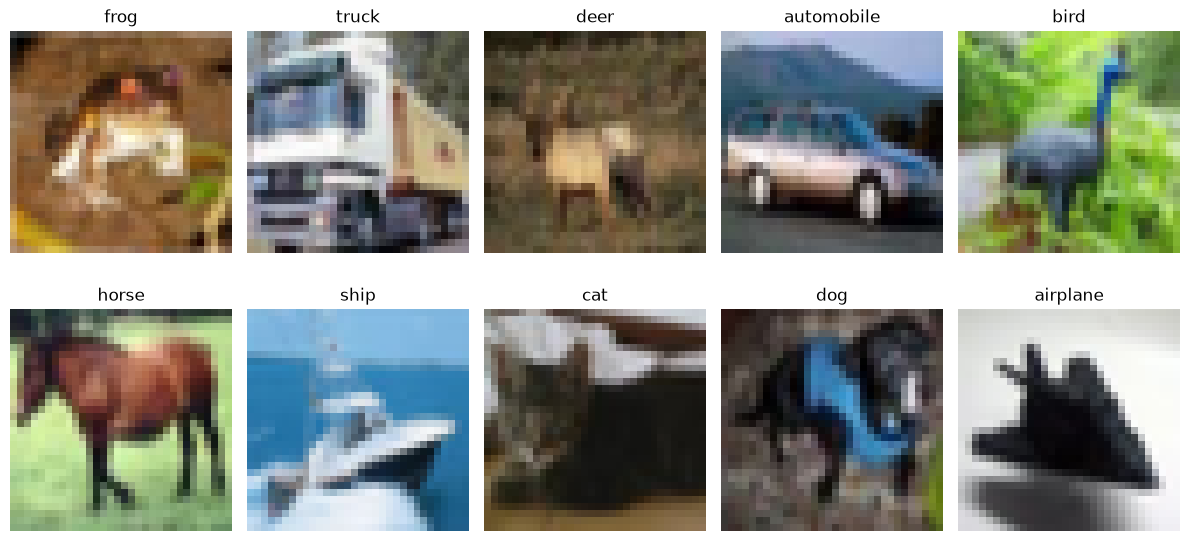

In [5]:
# CIFAR 10 datasetdagi imagelarni olib ko'ramiz.
import matplotlib.pyplot as plt

images_per_class = {} # har bir class uchun 1 ta image saqlash uchun dict
for img, label in ds:  # datasetdan rasmlar va ularning label(lar)ini olib olamiz
    class_name = classes[label] # class nomini olib olamiz
    if class_name not in images_per_class: # agar class nomi dict ichida bo'lmasa, uni qo'shamiz
        images_per_class[class_name] = img  # har bir class uchun 1 ta image saqlaymiz
    if len(images_per_class)==len(classes): break  # agar barcha classlar uchun 1 ta image saqlangan bo'lsa, loopni to'xtatamiz

#plt
plt.figure(figsize=(12,6))   # rasmlar uchun figure o'lchamini belgilaymiz
for idx, (class_name, img) in enumerate(images_per_class.items()): # har bir class nomi va unga tegishli image ni olamiz
    plt.subplot(2,5,idx+1)   # har bir image ni 2x5 gridda joylashtiramiz
    plt.imshow(img.permute(1,2,0)) # img tensorini (C,H,W) dan (H,W,C) ga o'zgartirib, rasmni ko'rsatamiz
    plt.title(class_name) # har bir image ostiga class nomini yozamiz
    plt.axis('off')   # har bir image uchun axislarni o'chiramiz
plt.tight_layout() # rasmlar orasidagi bo'shliqni moslashtiramiz
plt.show()  # rasmlarni ko'rsatamiz

In [6]:
bs = 128
tr_dl = DataLoader(dataset = tr_ds, batch_size = bs, shuffle = True, num_workers = 4)
vl_dl = DataLoader(dataset = vl_ds, batch_size = bs, shuffle = False, num_workers = 4)
ts_dl = DataLoader(dataset = ts_ds, batch_size = 1,  shuffle = False, num_workers = 4)

#AL Model with Linear Layers

In [ ]:
# CNN - convolution neural networks
# filter == kernel

In [7]:
import torch
from torch.nn import Conv2d, MaxPool2d
inp = torch.rand(1, 3, 32, 32) # 4D -> (bs, im_chs, im_h, im_w)
# 2 ni darajalari; 8 -> 16 -> 32
# stride -> filterning qadami
# conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 1, stride = 1) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 2 * 1 - 3) / 1] + 1 = 32
# conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 0, stride = 1) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 0 - 3) / 1] + 1 = 29 + 1 = 30

conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 1, stride = 2) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 2 - 3) / 2] + 1 = 15 + 1 = 16

mp = MaxPool2d(kernel_size = 2, stride = 2) # backpropda qatnashmaydi: trainable parametrlari yo'q
mp(inp).shape

#conv(inp).shape

torch.Size([1, 3, 16, 16])

In [8]:
from torch.nn import *

class CustomModel(Module):

  def __init__(self, in_fs, in_chs, out_fs, out_chs, ks, p, s,n_cls):
    super().__init__()

#  3 ta convolution layer va 2 ta linear layer
    self.conv_1 = Conv2d(in_channels = in_chs, out_channels = out_chs, kernel_size = ks, padding = p, stride = s)
    self.conv_2 = Conv2d(in_channels = out_chs, out_channels = out_chs * 2, kernel_size = ks, padding = p, stride = s)
    self.conv_3 = Conv2d(in_channels = out_chs * 2, out_channels = out_chs, kernel_size = ks, padding = p, stride = s)

    self.lin_layer = Linear(in_features = in_fs, out_features = out_fs)
    self.classifier = Linear(in_features = out_fs, out_features = n_cls)
    self.act = ReLU() # prelu, leaky relu, elu,...
    self.mp = MaxPool2d(kernel_size = 2, stride = 2)

  def forward(self, inp): 

    out = self.conv_1(inp)        # (bs, out_chs, im_h, im_w)
    out = self.mp(self.act(out))  # (bs, out_chs, im_h // 2, im_w // 2)
    out = self.conv_2(out)        # (bs, out_chs * 2, im_h // 2, im_w // 2)
    out = self.mp(self.act(out))  # (bs, out_chs * 2, im_h // 4, im_w // 4)

    bs = inp.shape[0]
    out = out.view(bs, -1)

    out = self.lin_layer(out)
    out = self.act(out)
    out = self.classifier(out)

    return out

inp = torch.rand(1,3,32,32)
out_fs = 256

m = CustomModel(in_chs = inp.shape[1], out_chs = 8, ks = 3, p = 1, s = 1, in_fs = 1024, out_fs = out_fs, n_cls = n_cls)
xom_bashorat = m(inp)
xom_bashorat.shape

torch.Size([1, 10])

In [ ]:
### Training Loop

In [9]:
# Modelimizda nechta parametr borligini kurishimiz muhim. Chunki modelimizda qancha parametr bo'lsa, shuncha ko'p xotira talab qilinadi va shuncha ko'p vaqt talab qilinadi. Shuning uchun modelimizda nechta parametr borligini hisoblaymiz.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model = m) # modelimiz buyerda m

267522

In [10]:
class CustomModel1(Module): 

  def __init__(self, in_fs, in_chs, out_fs, out_chs, ks, p, s, n_cls): 
    super().__init__()  # bu

#  3 ta convolution layer va 3 ta linear layer
    self.conv_1 = Conv2d(in_channels = in_chs, out_channels = out_chs, kernel_size = ks, padding = p, stride = s) 
    self.conv_2 = Conv2d(in_channels = out_chs, out_channels = out_chs * 2, kernel_size = ks, padding = p, stride = s) 
    self.conv_3 = Conv2d(in_channels = out_chs * 2, out_channels = out_chs * 8, kernel_size = ks, padding = p, stride = s) 

    self.lin_layer1 = Linear(in_features = in_fs, out_features = out_fs) 
    self.lin_layer2 = Linear(in_features = out_fs, out_features = out_fs // 2)
    self.classifier = Linear(in_features = out_fs // 2, out_features = n_cls)
    self.act = ReLU() # prelu, leaky relu, elu,...
    self.mp = MaxPool2d(kernel_size = 2, stride = 2)

  def forward(self, inp): 

    out = self.conv_1(inp)        # (bs, out_chs, im_h, im_w)
    out = self.mp(self.act(out))  # (bs, out_chs, im_h // 2, im_w // 2)
    out = self.conv_2(out)        # (bs, out_chs * 2, im_h // 2, im_w // 2)
    out = self.mp(self.act(out))  # (bs, out_chs * 2, im_h // 4, im_w // 4)
    out = self.conv_3(out)        # (bs, out_chs * 8, im_h // 4, im_w // 4)
    out = self.mp(self.act(out))  # (bs, out_chs * 8, im_h // 8, im_w // 8)

    bs = inp.shape[0] # batch size ni olishimiz kerak, chunki out tensorining birinchi o'lchami batch size bo'ladi. Shuning uchun bs = inp.shape[0] deb olamiz.
    out = out.view(bs, -1)  # out tensorini 2D ga o'zgartiramiz, chunki Linear layer faqat 2D input qabul qiladi. Shuning uchun out tensorini (bs, -1) ga o'zgartiramiz. -1 bu yerda avtomatik ravishda out tensorining qolgan o'lchamlari hisoblanadi.

    out = self.lin_layer1(out) # bu yerda out tensorini lin_layer1 ga uzatamiz, chunki lin_layer1 out_features ni oladi va out_features ni chiqaradi. Shuning uchun out tensorini lin_layer1 ga uzatamiz.
    out = self.act(out) # bu yerda out tensorini act ga uzatamiz, chunki act ReLU activation function ni ishlatadi va out tensorini ReLU ga uzatamiz. Shuning uchun out tensorini act ga uzatamiz.
    out = self.lin_layer2(out)
    out = self.act(out)
    out = self.classifier(out)
    return out
 
inp = torch.rand(1,3,32,32)
out_fs = 256
n_cls = len(classes)
m1 = CustomModel1(in_chs = inp.shape[1], out_chs = 8, in_fs = 1024, out_fs = out_fs, ks = 3, p = 1, s = 1, n_cls = n_cls)
xom_bashorat1 = m1(inp)
xom_bashorat1.shape

torch.Size([1, 10])

In [11]:
class CustomModel2(Module):
    def __init__(self, in_fs, out_fs, n_cls, in_chs, out_chs, ks, p, s):
        super().__init__()

        #  4 ta convolution layer  
        self.conv1 = Conv2d(in_channels= in_chs, out_channels=out_chs, kernel_size=ks, padding=p, stride=s)
        self.conv2 = Conv2d(in_channels= out_chs, out_channels=out_chs*2, kernel_size=ks, padding=p, stride=s)
        self.conv3 = Conv2d(in_channels= out_chs*2, out_channels=out_chs*4, kernel_size=ks, padding=p, stride=s)
        self.conv4 = Conv2d(in_channels= out_chs*4, out_channels=out_chs*8, kernel_size=ks, padding=p, stride=s)

        self.adaptive_pool = AdaptiveAvgPool2d((1,1))
        
        # 2 ta linear layer
        self.lin_layer = Linear(in_features=out_chs*8, out_features=out_fs)
        self.classifier = Linear(in_features=out_fs, out_features=n_cls)
        self.act = ReLU()
        self.mp = MaxPool2d(kernel_size=2, stride=2)

    def forward(self, inp):
        out = self.conv1(inp)
        out = self.mp(self.act(out))
        out = self.conv2(out)
        out = self.mp(self.act(out))
        out = self.conv3(out)
        out = self.mp(self.act(out))
        out = self.conv4(out)
        out = self.mp(self.act(out))

        out = self.adaptive_pool(out)

        bs = out.shape[0]
        out = out.view(bs, -1)
        out = self.lin_layer(out)
        out = self.act(out) 
        out = self.classifier(out)
        return out
    
inp = torch.rand(1,3,64,64)
out_fs = 256
n_cls = len(classes)
m2 = CustomModel2(in_chs = inp.shape[1], out_chs = 8, ks = 3, in_fs = 1024, p = 1, s = 1, out_fs = out_fs, n_cls = n_cls)
xom_bashorat2 = m2(inp)
xom_bashorat2.shape

torch.Size([1, 10])

In [12]:
class CustomModel2(Module):
    def __init__(self, in_fs, out_fs, n_cls, in_chs, out_chs, ks, p, s):
        super().__init__()

        #  4 ta convolution layer 
        self.conv1 = Conv2d(in_channels= in_chs, out_channels=out_chs, kernel_size=ks, padding=p, stride=s)
        self.conv2 = Conv2d(in_channels= out_chs, out_channels=out_chs*2, kernel_size=ks, padding=p, stride=s)
        self.conv3 = Conv2d(in_channels= out_chs*2, out_channels=out_chs*4, kernel_size=ks, padding=p, stride=s)
        self.conv4 = Conv2d(in_channels= out_chs*4, out_channels=out_chs*8, kernel_size=ks, padding=p, stride=s)

        self.adaptive_pool = AdaptiveAvgPool2d((1,1))

        # 3 ta linear layer
        self.lin_layer = Linear(in_features=out_chs*8, out_features=out_fs)
        self.lin_layer1 = Linear(in_features=out_fs, out_features=out_fs//2)
        self.classifier = Linear(in_features=out_fs//2, out_features=n_cls)
        self.act = ReLU()
        self.mp = MaxPool2d(kernel_size=2, stride=2)

    def forward(self, inp):
        out = self.conv1(inp)
        out = self.mp(self.act(out))
        out = self.conv2(out)
        out = self.mp(self.act(out))
        out = self.conv3(out)
        out = self.mp(self.act(out))
        out = self.conv4(out)
        out = self.mp(self.act(out))

        out = self.adaptive_pool(out)

        bs = out.shape[0]
        out = out.view(bs, -1)
        out = self.lin_layer(out)
        out = self.act(out)
        out = self.lin_layer1(out)
        out = self.act(out) 
        out = self.classifier(out)
        return out
    
inp = torch.rand(1,3,64,64)
out_fs = 256
n_cls = len(classes)
m3 = CustomModel2(in_chs = inp.shape[1], out_chs = 8, ks = 3, in_fs = 1024, p = 1, s = 1, out_fs = out_fs, n_cls = n_cls)
xom_bashorat3 = m3(inp)

Men enternetda biroz izlab ko'rgandim siz aytgandek 6 ta convolution layer bulishi mumkin, lekin ehtiyot bulish kerak ekan, sababi ko'plab resurslar talab qilarkan. GPU xotira ham ko'p ishlatilar ekan. Bundan tahqari Trening vaqti ham uzayish ehtimoli bor ekan.

In [40]:
epochs = 10
loss_fn = torch.nn.CrossEntropyLoss()
optimazor = torch.optim.Adam(params=m.parameters(), lr=1e-3)
for epoch in range(epochs):
    tr_epoch_acc = 0
    tr_epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javob = batch

        xom_bashorat = m(rasm)
        bashorat = torch.argmax(xom_bashorat, dim=1)

        loss = loss_fn(xom_bashorat, javob)
        tr_epoch_loss += loss.item()

        optimazor.zero_grad()
        loss.backward()
        optimazor.step()

        batch_acc = (bashorat == javob).sum().item()
        tr_epoch_acc += batch_acc

    print(f"{epoch+1}- epochdagi train loss: {tr_epoch_loss / len(tr_dl):.3f}")
    print(f"{epoch+1}- epochdagi train acc: {tr_epoch_acc / len(tr_dl.dataset):.3f}")

    with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javob = batch

            xom_bashorat = m(rasm)
            bashorat = torch.argmax(xom_bashorat, dim=1)
            loss = loss_fn(xom_bashorat, javob)
            vl_epoch_loss += loss.item()

            batch_acc = (bashorat == javob).sum().item()
            vl_epoch_acc  +=batch_acc

    print(f"{epoch+1}- epochdagi valid loss: {vl_epoch_loss/len(vl_dl):.3f}")
    print(f"{epoch+1}- epochdagi valid acc: {vl_epoch_acc/len(vl_dl.dataset):.3f}")

KeyboardInterrupt: 

In [41]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
i=1
for m in [m, m1, m2, m3]:
    print(f"{i}- paramater soni {count_parameters(m)}")
   
    i+=1

1- paramater soni 75354
2- paramater soni 307258
3- paramater soni 43738
4- paramater soni 75354


In [ ]:
epochs = 10
loss_fn = torch.nn.CrossEntropyLoss()
optimazor = torch.optim.Adam(params=m.parameters(), lr=1e-3)
for epoch in range(epochs):
    tr_epoch_acc = 0
    tr_epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javob = batch

        xom_bashorat = m(rasm)
        bashorat = torch.argmax(xom_bashorat, dim=1)

        loss = loss_fn(xom_bashorat, javob)
        tr_epoch_loss += loss.item()

        optimazor.zero_grad()
        loss.backward()
        optimazor.step()

        batch_acc = (bashorat == javob).sum().item()
        tr_epoch_acc += batch_acc

    print(f"{epoch+1}- epochdagi train loss: {tr_epoch_loss / len(tr_dl):.3f}")
    print(f"{epoch+1}- epochdagi train acc: {tr_epoch_acc / len(tr_dl.dataset):.3f}")

    with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javob = batch

            xom_bashorat = m(rasm)
            bashorat = torch.argmax(xom_bashorat, dim=1)
            loss = loss_fn(xom_bashorat, javob)
            vl_epoch_loss += loss.item()

            batch_acc = (bashorat == javob).sum().item()
            vl_epoch_acc  +=batch_acc

    print(f"{epoch+1}- epochdagi valid loss: {vl_epoch_loss/len(vl_dl):.3f}")
    print(f"{epoch+1}- epochdagi valid acc: {vl_epoch_acc/len(vl_dl.dataset):.3f}")

KeyboardInterrupt: 

 b) Yuqorida yaratilgan 4 ta modelning parameterlar sonini solishtiring

In [ ]:
epochs = 10
loss_fn = torch.nn.CrossEntropyLoss()
optimazor = torch.optim.Adam(params=m1.parameters(), lr=1e-3)
for epoch in range(epochs):
    tr_epoch_acc = 0
    tr_epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javob = batch

        xom_bashorat1 = m1(rasm)
        bashorat = torch.argmax(xom_bashorat1, dim=1)

        loss = loss_fn(xom_bashorat1, javob)
        tr_epoch_loss += loss.item()

        optimazor.zero_grad()
        loss.backward()
        optimazor.step()

        batch_acc = (bashorat == javob).sum().item()
        tr_epoch_acc += batch_acc

    print(f"{epoch+1}- epochdagi train loss: {tr_epoch_loss / len(tr_dl):.3f}")
    print(f"{epoch+1}- epochdagi train acc: {tr_epoch_acc / len(tr_dl.dataset):.3f}")

    with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javob = batch

            xom_bashorat1 = m1(rasm)
            bashorat = torch.argmax(xom_bashorat1, dim=1)
            loss = loss_fn(xom_bashorat1, javob)
            vl_epoch_loss += loss.item()

            batch_acc = (bashorat == javob).sum().item()
            vl_epoch_acc  +=batch_acc

    print(f"{epoch+1}- epochdagi valid loss: {vl_epoch_loss/len(vl_dl):.3f}")
    print(f"{epoch+1}- epochdagi valid acc: {vl_epoch_acc/len(vl_dl.dataset):.3f}")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x1174ad8a0>
Traceback (most recent call last):
  File "/Users/apple/Course/.venv311/lib/python3.11/site-packages/torch/utils/data/dataloader.py", line 1479, in __del__
    self._shutdown_workers()
  File "/Users/apple/Course/.venv311/lib/python3.11/site-packages/torch/utils/data/dataloader.py", line 1443, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/local/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.11/lib/python3.11/multiprocessing/process.py", line 149, in join
    res = self._popen.wait(timeout)
          ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.11/lib/python3.11/multiprocessing/popen_fork.py", line 40, in wait
    if not wait([self.sentinel], timeout):
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/Cellar/python@3.11/3.11.16/Frameworks/Python.framework/Versions/3.1

KeyboardInterrupt: 

In [ ]:
epochs = 10
loss_fn = torch.nn.CrossEntropyLoss()
optimazor = torch.optim.Adam(params=m2.parameters(), lr=1e-3)
for epoch in range(epochs):
    tr_epoch_acc = 0
    tr_epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javob = batch

        xom_bashorat2 = m2(rasm)
        bashorat = torch.argmax(xom_bashorat2, dim=1)

        loss = loss_fn(xom_bashorat2, javob)
        tr_epoch_loss += loss.item()

        optimazor.zero_grad()
        loss.backward()
        optimazor.step()

        batch_acc = (bashorat == javob).sum().item()
        tr_epoch_acc += batch_acc

    print(f"{epoch+1}- epochdagi train loss: {tr_epoch_loss / len(tr_dl):.3f}")
    print(f"{epoch+1}- epochdagi train acc: {tr_epoch_acc / len(tr_dl.dataset):.3f}")

    with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javob = batch

            xom_bashorat2 = m2(rasm)
            bashorat = torch.argmax(xom_bashorat2, dim=1)
            loss = loss_fn(xom_bashorat2, javob)
            vl_epoch_loss += loss.item()

            batch_acc = (bashorat == javob).sum().item()
            vl_epoch_acc  +=batch_acc

    print(f"{epoch+1}- epochdagi valid loss: {vl_epoch_loss/len(vl_dl):.3f}")
    print(f"{epoch+1}- epochdagi valid acc: {vl_epoch_acc/len(vl_dl.dataset):.3f}")

In [38]:
epochs = 10
loss_fn = torch.nn.CrossEntropyLoss()
optimazor = torch.optim.Adam(params=m3.parameters(), lr=1e-3)
for epoch in range(epochs):
    tr_epoch_acc = 0
    tr_epoch_loss = 0
    vl_epoch_acc = 0
    vl_epoch_loss = 0

    for idx, batch in enumerate(tr_dl):
        rasm, javob = batch

        xom_bashorat3 = m3(rasm)
        bashorat = torch.argmax(xom_bashorat3, dim=1)

        loss = loss_fn(xom_bashorat3, javob)
        tr_epoch_loss += loss.item()

        optimazor.zero_grad()
        loss.backward()
        optimazor.step()

        batch_acc = (bashorat == javob).sum().item()
        tr_epoch_acc += batch_acc

    print(f"{epoch+1}- epochdagi train loss: {tr_epoch_loss / len(tr_dl):.3f}")
    print(f"{epoch+1}- epochdagi train acc: {tr_epoch_acc / len(tr_dl.dataset):.3f}")

    with torch.no_grad():
        for idx, batch in enumerate(vl_dl):
            rasm, javob = batch

            xom_bashorat3 = m3(rasm)
            bashorat = torch.argmax(xom_bashorat3, dim=1)
            loss = loss_fn(xom_bashorat3, javob)
            vl_epoch_loss += loss.item()

            batch_acc = (bashorat == javob).sum().item()
            vl_epoch_acc  +=batch_acc

    print(f"{epoch+1}- epochdagi valid loss: {vl_epoch_loss/len(vl_dl):.3f}")
    print(f"{epoch+1}- epochdagi valid acc: {vl_epoch_acc/len(vl_dl.dataset):.3f}")

KeyboardInterrupt: 

In [42]:
for i in [m, m1, m2, m3]:
    print(i.eval())

CustomModel2(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (lin_layer): Linear(in_features=64, out_features=256, bias=True)
  (lin_layer1): Linear(in_features=256, out_features=128, bias=True)
  (classifier): Linear(in_features=128, out_features=10, bias=True)
  (act): ReLU()
  (mp): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
CustomModel1(
  (conv_1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv_3): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (lin_layer1): Linear(in_features=1024, out_features=256, bias=True)
  (l

In [45]:
ts_dl = DataLoader(  ts_ds, batch_size=32, shuffle=False, num_workers=0)

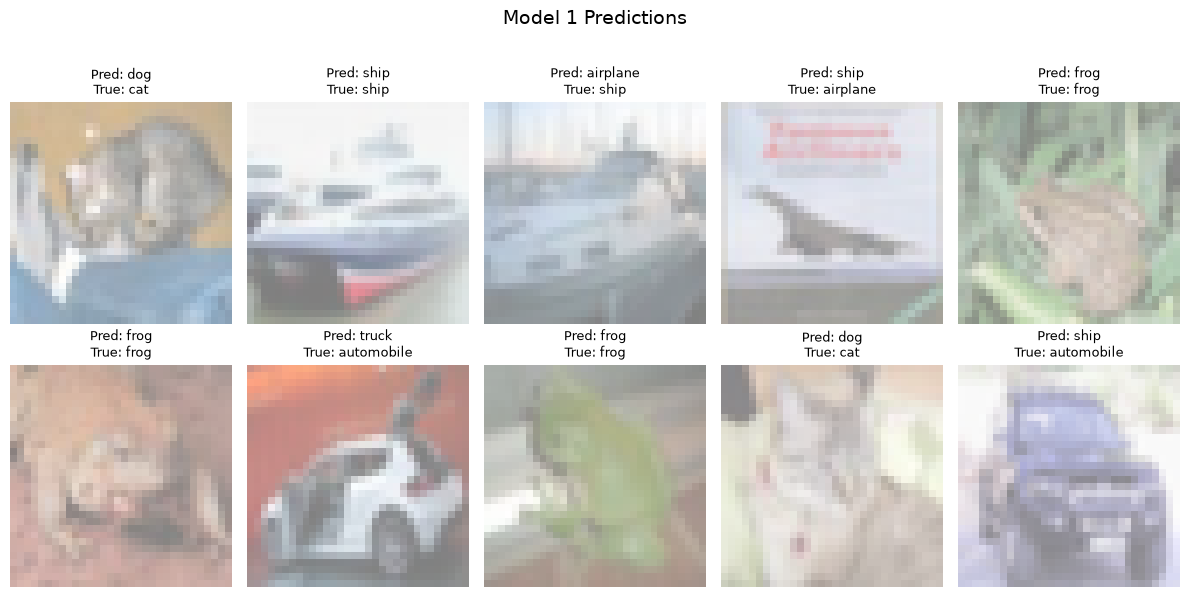

🔹 Accuracy on 10 test images for Model 1: 40.00%



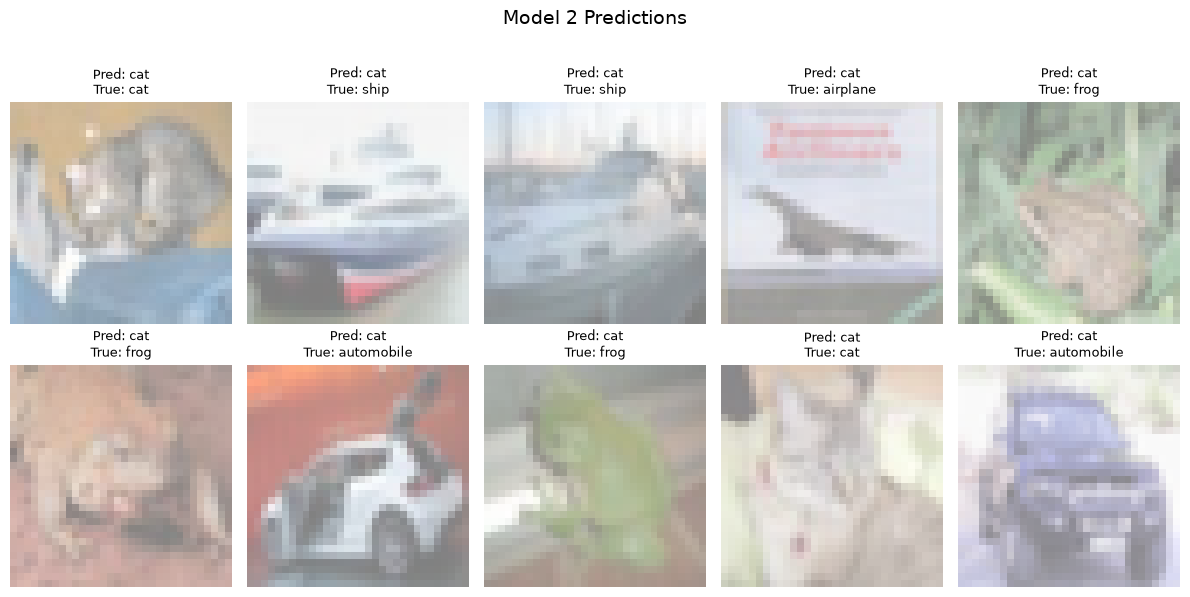

🔹 Accuracy on 10 test images for Model 2: 20.00%



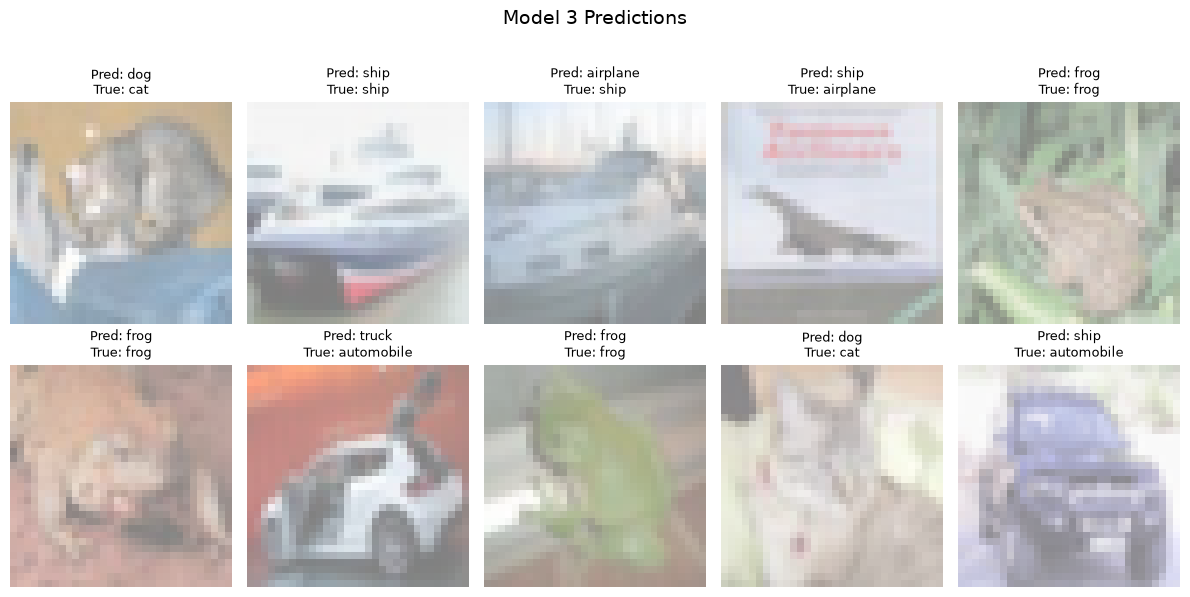

🔹 Accuracy on 10 test images for Model 3: 40.00%



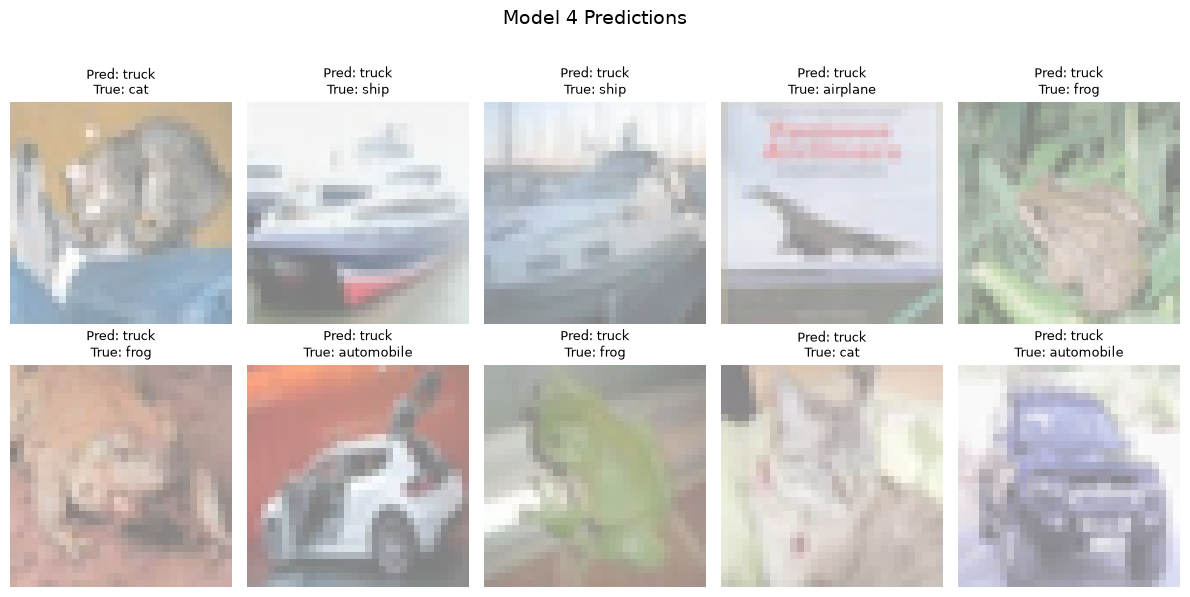

🔹 Accuracy on 10 test images for Model 4: 0.00%



In [46]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

# List of CNN modellar
custom_cnn_models = [m, m2, m3, m1]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


test_images, test_labels = next(iter(ts_dl))

test_images, test_labels = test_images.to(device), test_labels.to(device)


for idx, model in enumerate(custom_cnn_models):
    model.eval()

    with torch.no_grad():
        test_outputs = model(test_images[:10])   
        predictions = torch.argmax(test_outputs, dim=1)

    
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    axes = axes.flatten()

    correct_count = 0
    for i in range(10):
        img = test_images[i].cpu().numpy().transpose(1, 2, 0)
        img = (img * 0.5) + 0.5   
        pred_label = classes[predictions[i].item()]
        true_label = classes[test_labels[i].item()]

        if pred_label == true_label:
            correct_count += 1

        axes[i].imshow(img.squeeze())  # works for 1ch or 3ch
        axes[i].set_title(f"Pred: {pred_label}\nTrue: {true_label}", fontsize=9)
        axes[i].axis("off")

    plt.suptitle(f"Model {idx+1} Predictions", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

    accuracy = correct_count / 10 * 100
    print(f"🔹 Accuracy on 10 test images for Model {idx+1}: {accuracy:.2f}%\n")

kompyuterim mac air bulgani bois kuplab datalarni sig'dira olmayopti va run qilish uchun juda kup vaqt sarflayopman manashu vazifani qilish jarayonida ham kup xatolik buldi data  yuklab buyicha sizda ham men yuborgan vazifada xatoliklar bulsa ayting. 